# 03 — Sequential retrieval with the recipe from 01

The **settings and complete recipe are written below and editable here**. They were initialized from notebook 01: scans 2871/2872, crop 500, binning 1, modes [1, 2], support erosion 0 / dilation 6, saturated HAPRE 700 + ER 50, then loop ER 50. No settings or results are loaded from notebooks 01 or 02. Only the preprocessing cache and the painted mask/support PNGs are required.

Support preparation is shown explicitly: load pure-red PNG pixels, map to the cached grid, shift, optionally add the circle, erode, dilate, and recenter. The fixed detector mask is the same union as 01: painted PNG plus automatic masks for saturation and `STATE_POINT_NUMBER=25`. All states use this same binary mask and support. The driver additionally excludes nonpositive intensities per state, exactly as in 01; both `mask` and `effective_mask` are saved. Diagnostic holograms show the final crop/binned mask in cyan.

The retrieval cell calls the **same two-observation driver as 01** for every loop point using the explicit `recipe`. This repeats the saturated stages for each pair to preserve the complete recipe's initialization/coherence behavior and takes longer than the old approximate warmup. Only one pair stays in memory. No loop reconstruction seeds the next point.

Extra Poisson refinement is **disabled by default**, since 01 does not use it. For compatibility with the result viewer, `warmup_fields` contains the 01-style result and `poisson_fields` is an identical copy while disabled (`status=disabled_matching_01`). Enabling refinement intentionally changes the result.

Display propagation, phase and ROI are also editable below, initialized from 01. PNG/GIF contrast is shared across the sequence; different autoscaling can change appearance without changing the complex reconstruction. Outputs retain per-state diagnostics, full complex arrays, native-resolution images, recipe/settings and source mask/support snapshots. Existing results are preserved in separate timestamped output directories.

`MODE_SUPPORT_CENTER="image"` scales the entire support about the image center, including distances between apertures. Only an enlarged mode that needs it is translated as a whole to fit; the factor-1 mask stays fixed. The cache/QA cell previews all modal supports and their translations. If the expanded support is wider than the available field, translation cannot make it fit and the notebook raises an error instead of clipping it.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, csv
import h5py
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, GifImagePlugin
from IPython.display import display

HERE = Path.cwd()
if not (HERE / "reconstruction_inputs.py").is_file():
    HERE = HERE / "aperiodic_ajajas"
HERE = HERE.resolve()
sys.path.insert(0, str(HERE.parent))
from aperiodic_ajajas.result_io import prepare_painted_detector_mask, painted_cache_mask, save_complex_reconstructions
from aperiodic_ajajas.reconstruction_inputs import detector_file_point_indices, fit_reference_intensity
from library import fthcore as fth
from library import phase_retrieval_geometry as geometry
from library import poisson_refinement as poisson
from library import phase_retrieval_core_unified as pr
from library.retrieval_progress import retrieval_progress

# Editable settings, copied from notebook 01 on 2026-09-30.
# This notebook does not load settings or recipes from another notebook.



SATURATED_SCAN = 2871
LOOP_SCAN = 2872
DISPLAY_PROP_UM = 2.05
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
roi=np.s_[215:373,267:420]
SUPPORT_CENTER_RADIUS = 0.0
STATE_POINT_NUMBER = 25  # Fix 01's mask union for ALL states using this reference point.



SATURATED_SCAN = 2923
LOOP_SCAN = 2924
DISPLAY_PROP_UM = 2.05
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0
DISPLAY_PROP_DX=0
roi=np.s_[225:383,257:410]
SUPPORT_CENTER_RADIUS = 10.0
STATE_POINT_NUMBER = 25  # Fix 01's mask union for ALL states using this reference point.



SATURATED_SCAN = 2923
LOOP_SCAN = 2925
DISPLAY_PROP_UM = 2.05
DISPLAY_PHASE_RAD = -0.76
DISPLAY_PROP_DY=0
DISPLAY_PROP_DX=0
roi=np.s_[225:383,257:410]
SUPPORT_CENTER_RADIUS = 10.0
STATE_POINT_NUMBER = 25  # Fix 01's mask union for ALL states using this reference point.



SATURATED_SCAN = 2919
LOOP_SCAN = 2920
SUPPORT_DILATION = 1
SUPPORT_EROSION = 0
DISPLAY_PROP_DY=0.9
DISPLAY_PROP_DX=0
DISPLAY_PROP_UM = 2.05  # Copy2 active CDI loop display setting.
DISPLAY_PHASE_RAD = -0.76+np.pi/4
roi=np.s_[225:383,257:410]
SUPPORT_CENTER_RADIUS = 10.0  # Cached-grid pixels; 0 disables the central reference circle.
STATE_POINT_NUMBER = 25





MODES = [1, 2]
MODE_SUPPORT_CENTER = "image"  # Scale the entire support, including aperture separations.
RETRIEVAL_CROP = 500
RETRIEVAL_BINNING = 1
USE_PARTIAL_COHERENCE = False
NORMALIZE_LOOP_INTENSITY = False
HOLOGRAM_OFFSET = 0.0
SUPPORT_SHIFT = (0, 0)
SUPPORT_PNG = HERE / f"supportmask_{SATURATED_SCAN}.png"

SUPPORT_EROSION = 0
SUPPORT_DILATION = 0
MASK_PIXEL_PNG = HERE / f"mask_pixel_{SATURATED_SCAN}.png"

DISPLAY_SETUP = {"ccd_dist": 0.125, "px_size": 11e-6}  # Energy is read from the cache.
DISPLAY_ROI = roi

CACHE = HERE / "processed" / f"preprocessed_{LOOP_SCAN}_{SATURATED_SCAN}.h5"
OUTPUT_DIR = HERE / "processed" / f"scans_{SATURATED_SCAN}_{LOOP_SCAN}"
OUTPUT_ROOT = OUTPUT_DIR / "sequential"
RETRIEVAL_POINT_NUMBERS = None  # None processes all acquisition points.
LOOP_EXCLUDE_POINT_NUMBERS = []
SHOW_EVERY = 10
RUN_POISSON_REFINEMENT = False  # 01 has no Poisson polishing; keep off for matching results.
POISSON_STEPS = 50
POISSON_LEARNING_RATE = 1.0
POISSON_REFINE_MODES = [0]
if RUN_POISSON_REFINEMENT and USE_PARTIAL_COHERENCE:
    raise ValueError("Extra Poisson refinement is only supported for coherent retrieval")
SAVE_INDIVIDUAL_MODE_PNGS = True
GIF_FRAME_DURATION_MS = 200
DIFFERENCE_COLOR_LIMITS = None
DIAGNOSTIC_ROI_PADDING = 0.15
FOCUS_OVERRIDE = {}
FOCUS_ROI_OVERRIDE = None
SATURATED_CURRENT_A = None
USE_PAINTED_MASK_PIXEL = True
# Full editable recipe, matching 01. Every pair uses this exact recipe.
recipe = pr.default_phase_retrieval_recipe()
# Reconstruct the saturated reference with HAPRE+ER, then start the loop
# state from that result for a short ER update.
recipe.update(
    algorithm_list=(["HAPRE", "ER", "ER", "HAPRE", "ER", "ER"]
                    if USE_PARTIAL_COHERENCE else ["HAPRE", "ER", "ER"]),
    number_iterations=([700, 50, 50, 700, 50, 50]
                       if USE_PARTIAL_COHERENCE else [700, 50, 50]),
    helicity=(["saturated", "saturated", "loop", "saturated", "saturated", "loop"]
              if USE_PARTIAL_COHERENCE else ["saturated", "saturated", "loop"]),
    beta_zero=[0.5] * (6 if USE_PARTIAL_COHERENCE else 3),
    beta_mode=(["arctan", "const", "const", "arctan", "const", "const"]
               if USE_PARTIAL_COHERENCE else ["arctan", "const", "const"]),
    alpha_zero=[0.5] * (6 if USE_PARTIAL_COHERENCE else 3),
    alpha_mode=["const"] * (6 if USE_PARTIAL_COHERENCE else 3),
    RL_its=([0]*3 + [50]*3) if USE_PARTIAL_COHERENCE else [0]*3,
    RL_freqs=([1e9]*3 + [20]*3) if USE_PARTIAL_COHERENCE else [1e9]*3,
    TV_freqs=[10] * (6 if USE_PARTIAL_COHERENCE else 3),
    plot_every=[1e9] * (6 if USE_PARTIAL_COHERENCE else 3),
    average_img=[3] * (6 if USE_PARTIAL_COHERENCE else 3),
    Fourier_last=[True] * (6 if USE_PARTIAL_COHERENCE else 3),
    Startimage=([None, "saturated", "saturated", "saturated", "saturated", "saturated"]
                if USE_PARTIAL_COHERENCE else [None, "saturated", "saturated"]),
    Startgamma=([None]*3 + [None, "saturated", "saturated"]
                if USE_PARTIAL_COHERENCE else [None]*3),
    output=([False, False, False, False, True, True]
            if USE_PARTIAL_COHERENCE else [False, True, True]),
    hologram_intensity_cutoff_vmin=-1,
    normalize_startimage_between_holograms=True,
    crop=RETRIEVAL_CROP, binning=RETRIEVAL_BINNING, roi=None,
    return_format="dict", modes=MODES, recenter_modal_supports=True,
    mode_support_center=MODE_SUPPORT_CENTER,
)

print("Scans:", SATURATED_SCAN, LOOP_SCAN, "fixed mask reference point:", STATE_POINT_NUMBER)
print("Crop/bin:", RETRIEVAL_CROP, RETRIEVAL_BINNING,
      "support erosion/dilation:", SUPPORT_EROSION, SUPPORT_DILATION)
print("Recipe:", json.dumps(recipe, default=str, indent=2))
print("Extra Poisson refinement:", RUN_POISSON_REFINEMENT)

def select_numbers(available, requested=None, step=1, exclude=()):
    """Return positions in available, selecting acquisition numbers, not positions."""
    available = [int(v) for v in available]
    if len(set(available)) != len(available):
        raise ValueError('Duplicate acquisition point numbers')
    if requested is None:
        if type(step) is not int or step < 1:
            raise ValueError('Selection step must be a positive integer')
        result = [i for i, value in enumerate(available) if value not in exclude][::step]
    else:
        if not requested or any(type(v) is not int or v < 0 for v in requested):
            raise ValueError('Selection must be a nonempty list of nonnegative integers')
        if len(set(requested)) != len(requested):
            raise ValueError('Duplicate requested indices')
        missing = set(requested) - set(available)
        if missing:
            raise ValueError(f'Requested indices are unavailable: {sorted(missing)}')
        result = [available.index(v) for v in requested]
    if not result:
        raise ValueError('Selection is empty')
    return result



Scans: 2919 2920 fixed mask reference point: 25
Crop/bin: 500 1 support erosion/dilation: 0 0
Recipe: {
  "algorithm_list": [
    "HAPRE",
    "ER",
    "ER"
  ],
  "number_iterations": [
    700,
    50,
    50
  ],
  "helicity": [
    "saturated",
    "saturated",
    "loop"
  ],
  "beta_zero": [
    0.5,
    0.5,
    0.5
  ],
  "beta_mode": [
    "arctan",
    "const",
    "const"
  ],
  "alpha_zero": [
    0.5,
    0.5,
    0.5
  ],
  "alpha_mode": [
    "const",
    "const",
    "const"
  ],
  "RL_its": [
    0,
    0,
    0
  ],
  "RL_freqs": [
    1000000000.0,
    1000000000.0,
    1000000000.0
  ],
  "TV_freqs": [
    10,
    10,
    10
  ],
  "plot_every": [
    1000000000.0,
    1000000000.0,
    1000000000.0
  ],
  "average_img": [
    3,
    3,
    3
  ],
  "Fourier_last": [
    true,
    true,
    true
  ],
  "output": [
    false,
    true,
    true
  ],
  "Nmodes": 1,
  "modes": [
    1,
    2
  ],
  "recenter_modal_supports": true,
  "mode_support_center": "image",
  "

## Inspect cache metadata and support (no loop image stack is loaded)

Paint detector exclusions pure red, save and rerun this cell: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/mask_pixel_2919.png
Painted excluded pixels: 307417
Fixed 01 detector mask: 307417 excluded source pixels
Adjusted support: /home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/supportmask_2919.png {'erosion': 0, 'dilation': 0, 'order': 'circle_then_erosion_then_dilation', 'grid': 'cached_object_pixels', 'center_radius': 10.0, 'support_png': '/home/riccardo/Desktop/Github/FTH-Phase-Retrieval-2609-SOLEIL-SEXTANTS/aperiodic_ajajas/supportmask_2919.png'}
Selected points: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 23, 24, 25, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 86, 87, 88, 89, 90, 91, 92, 93,

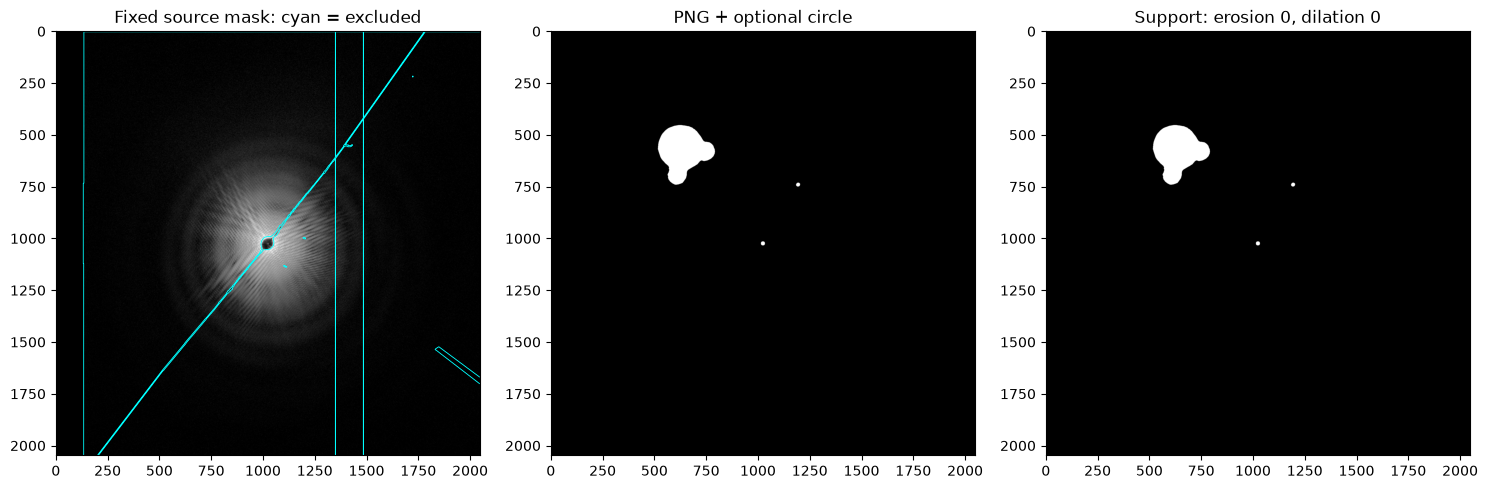

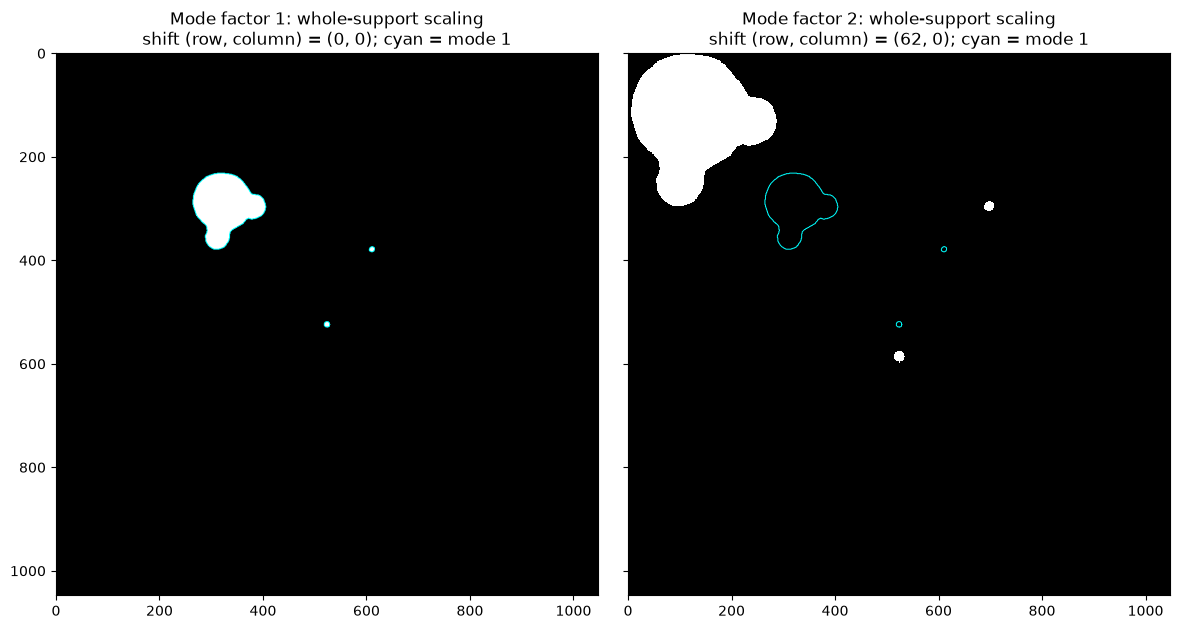

Modal support translations: [(0, 0), (62, 0)]


In [2]:
with h5py.File(CACHE, "r") as h:
    cache_config = json.loads(h.attrs["config_json"])
    if (cache_config.get("saturated_scan") != SATURATED_SCAN
            or cache_config.get("loop_scan") != LOOP_SCAN):
        raise ValueError("Cache scan numbers do not match notebook settings")
    if (cache_config.get("crop_raw_pixels") != 0
            or cache_config.get("binning") != 1
):
        raise ValueError("Re-run notebook 00 for the selected scans: incompatible cached geometry")
    n_images = h["loop_holograms"].shape[0]
    source_shape = h["loop_holograms"].shape[-2:]
    file_names = h["loop_file_names"].asstr()[:]
    point_numbers = detector_file_point_indices(file_names)
    currents = h["loop_current_A"][()]
    energy_ev = float(h.attrs["photon_energy_eV"])
    saturated_currents = (h["saturated_current_A"][()] if "saturated_current_A" in h
                          else np.array([], dtype=float))
    saturated_source_files = (h["saturated_file_names"].asstr()[:].tolist()
                              if "saturated_file_names" in h else [])
    saturated_current = (float(SATURATED_CURRENT_A) if SATURATED_CURRENT_A is not None
                         else float(np.mean(saturated_currents)) if np.size(saturated_currents)
                         else float("nan"))
    saturated_current_source = ("explicit measured override" if SATURATED_CURRENT_A is not None
                                else "cache selected saturated point currents (mean)" if np.size(saturated_currents)
                                else "unavailable in source cache")
    painted_detector_mask = (prepare_painted_detector_mask(h["saturated_hologram"][()], MASK_PIXEL_PNG)
                             if USE_PAINTED_MASK_PIXEL else np.zeros(source_shape, dtype=bool))
    print("Paint detector exclusions pure red, save and rerun this cell:", MASK_PIXEL_PNG)
    print("Painted excluded pixels:", int(painted_detector_mask.sum()))

    reference_mask = painted_cache_mask(h, None, painted_detector_mask)
    if "saturated_automatic_mask" not in h:
        print("Legacy combined cache masks ignored. Re-run 00 to retain automatic saturation exclusions.")
if len(point_numbers) != n_images or len(currents) != n_images:
    raise ValueError("Cache image, filename and current counts disagree")
if n_images == 0:
    raise ValueError("Empty loop cache")
# Load the painted PNG here, independently of the preprocessing cache.
from PIL import Image
from scipy.ndimage import zoom, binary_erosion, binary_dilation
painted_rgb = np.asarray(Image.open(SUPPORT_PNG).convert("RGB"))
painted_support = np.all(painted_rgb == (255, 0, 0), axis=-1)
if not painted_support.any():
    raise ValueError(f"No pure-red support pixels in {SUPPORT_PNG}")
support_png_grid = zoom(painted_support.astype(float),
                       np.asarray(source_shape) / np.asarray(painted_support.shape), order=3) > 0.5
support_used = np.roll(support_png_grid, shift=SUPPORT_SHIFT, axis=(0, 1))
if not np.isfinite(SUPPORT_CENTER_RADIUS) or SUPPORT_CENTER_RADIUS < 0:
    raise ValueError("SUPPORT_CENTER_RADIUS must be finite and nonnegative")
if SUPPORT_CENTER_RADIUS > 0:
    yy, xx = np.ogrid[:source_shape[0], :source_shape[1]]
    cy, cx = np.asarray(source_shape) // 2
    support_used |= (yy - cy)**2 + (xx - cx)**2 <= SUPPORT_CENTER_RADIUS**2
for name, iterations in (("SUPPORT_EROSION", SUPPORT_EROSION),
                         ("SUPPORT_DILATION", SUPPORT_DILATION)):
    if type(iterations) is not int or iterations < 0:
        raise ValueError(f"{name} must be a nonnegative integer")
support_before_adjustment = support_used.astype(bool).copy()
support_after_adjustment = support_before_adjustment.copy()
if SUPPORT_EROSION > 0:
    support_after_adjustment = binary_erosion(support_after_adjustment, iterations=SUPPORT_EROSION)
if SUPPORT_DILATION > 0:
    support_after_adjustment = binary_dilation(support_after_adjustment, iterations=SUPPORT_DILATION)
if not support_after_adjustment.any():
    raise ValueError("Adjusted support is empty; reduce SUPPORT_EROSION")
support_adjustment = dict(erosion=SUPPORT_EROSION, dilation=SUPPORT_DILATION,
                          order="circle_then_erosion_then_dilation", grid="cached_object_pixels",
                          center_radius=float(SUPPORT_CENTER_RADIUS), support_png=str(SUPPORT_PNG))
support_used = support_after_adjustment.astype(np.uint8)
# Recenter once on the cached object grid, exactly as in 01.
source_support, support_source_shift = geometry.recenter_source_support(
    support_used, RETRIEVAL_CROP, RETRIEVAL_BINNING,
)
DISPLAY_SETUP = {**DISPLAY_SETUP, "energy": energy_ev}
indices = select_numbers(point_numbers, RETRIEVAL_POINT_NUMBERS,
                         exclude=LOOP_EXCLUDE_POINT_NUMBERS)
# Fix the same source mask as 01 for every state, including its reference union.
RESOLVED_MASK_REFERENCE_POINT_NUMBER = STATE_POINT_NUMBER
comparison_cache_index = select_numbers(point_numbers, [STATE_POINT_NUMBER])[0]
observation_indices = [None] + indices

with h5py.File(CACHE, "r") as cache:
    mask_pixel = (painted_cache_mask(cache, None, painted_detector_mask)
                          | painted_cache_mask(cache, comparison_cache_index,
                                               painted_detector_mask)).astype(np.uint8)
print("Fixed 01 detector mask:", int(mask_pixel.sum()), "excluded source pixels")
print("Adjusted support:", SUPPORT_PNG, support_adjustment)
print("Selected points:", [int(point_numbers[i]) for i in indices])
print("Each point runs the complete 01 saturated + loop recipe, with fixed masks/support.")
focus_settings = dict(focus_um=float(DISPLAY_PROP_UM), phase_rad=float(DISPLAY_PHASE_RAD),
                      dx=DISPLAY_PROP_DX, dy=DISPLAY_PROP_DY)
focus_settings_source = "03 editable display settings (initialized from 01)"
focus_roi = DISPLAY_ROI
if set(FOCUS_OVERRIDE) - focus_settings.keys():
    raise ValueError("Unknown FOCUS_OVERRIDE key")
focus_settings.update(FOCUS_OVERRIDE)
DISPLAY_PROP_UM = focus_settings["focus_um"]
DISPLAY_PHASE_RAD = focus_settings["phase_rad"]
if FOCUS_ROI_OVERRIDE is not None:
    focus_roi = FOCUS_ROI_OVERRIDE
print("Display:", focus_settings, "ROI:", focus_roi)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
with h5py.File(CACHE, "r") as cache:
    reference_preview = cache["saturated_hologram"][()]
axes[0].imshow(np.log1p(np.maximum(reference_preview, 0)), cmap="gray", origin="upper")
if mask_pixel.any():
    axes[0].contour(mask_pixel, levels=[0.5], colors="cyan", linewidths=0.6)
axes[0].set_title("Fixed source mask: cyan = excluded")
axes[1].imshow(support_before_adjustment, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("PNG + optional circle")
axes[2].imshow(support_after_adjustment, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Support: erosion {SUPPORT_EROSION}, dilation {SUPPORT_DILATION}")
plt.tight_layout()
plt.show()
# Preview the exact retrieval-grid modal geometry before starting the recipe.
_, preview_mask, preview_support, _, _ = geometry.prepare(
    reference_preview[None], mask_pixel, source_support,
    dict(crop=recipe["crop"], binning=recipe["binning"], roi=None),
)
preview_modal_supports, preview_modal_shifts = geometry.recenter_modal_supports(
    preview_support, recipe["modes"], center=recipe["mode_support_center"],
)
fig_modes, mode_axes = plt.subplots(1, len(MODES), figsize=(6 * len(MODES), 6),
                                   squeeze=False, sharex=True, sharey=True)
for ax, factor, modal_support, modal_shift in zip(
        mode_axes.flat, MODES, preview_modal_supports, preview_modal_shifts):
    ax.imshow(modal_support, cmap="gray", vmin=0, vmax=1, origin="upper",
              interpolation="nearest")
    ax.contour(preview_modal_supports[0], levels=[0.5], colors="cyan", linewidths=0.7)
    ax.set_title(f"Mode factor {factor}: whole-support scaling\n"
                 f"shift (row, column) = {modal_shift}; cyan = mode 1")
fig_modes.tight_layout()
plt.show()
print("Modal support translations:", preview_modal_shifts)
del reference_preview, preview_mask, preview_support



## Diagnostics and exports


In [3]:
def display_object(field):
    return fth.reconstructCDI(fth.propagate(
        field, DISPLAY_PROP_UM * 1e-6, experimental_setup=DISPLAY_SETUP,
    )) * np.exp(1j * DISPLAY_PHASE_RAD)


def save_plots(folder, label, measured, mask, warmup, result, histories, show=False):
    valid = poisson.valid_pixels(measured, mask)
    predictions = [poisson.predicted_intensity(x) for x in (warmup, result.fields)]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), layout="constrained")
    vmax = np.percentile(np.log1p(measured[valid]), 99.5)
    # Use the actual retrieval-grid mask, after all crop/bin and mask unions.
    excluded = np.asarray(mask) != 0
    if excluded.shape != measured.shape:
        raise ValueError("Diagnostic mask must match the measured hologram grid")
    rows, columns = measured.shape
    # Padding closes contours at image edges, including an entirely masked grid.
    contour_mask = np.pad(excluded.astype(np.uint8), 1, constant_values=0)
    for ax, values, title in zip(axes[0], [measured] + predictions, ["Measured", "01 retrieval", "Poisson" if RUN_POISSON_REFINEMENT else "Final (Poisson off)"]):
        ax.imshow(np.log1p(np.maximum(values, 0)), cmap="magma", vmin=0, vmax=vmax,
                  origin="upper")
        if excluded.any():
            ax.contour(np.arange(-1, columns + 1), np.arange(-1, rows + 1),
                       contour_mask, levels=[0.5], colors="cyan", linewidths=0.8)
        ax.set_xlim(-0.5, columns - 0.5)
        ax.set_ylim(rows - 0.5, -0.5)
        ax.set_title(title + " — log(1 + intensity)")
        ax.text(0.02, 0.02, f"Cyan: mask_pixel = 1 ({excluded.mean():.1%})",
                transform=ax.transAxes, color="cyan", fontsize=8,
                bbox=dict(facecolor="black", alpha=0.65, edgecolor="none"))
    residual = np.where(valid, predictions[1] - measured, np.nan)
    lim = max(float(np.nanpercentile(np.abs(residual), 99)), 1e-12)
    im = axes[1, 0].imshow(residual, cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=axes[1, 0]); axes[1, 0].set_title("Refined − measured (valid pixels)")
    for key in ("diffraction", "support"):
        values = np.concatenate([record[key].ravel() for record in histories])
        axes[1, 1].plot(values, label=key)
    axes[1, 1].legend(); axes[1, 1].set_title("01 recipe sampled errors")
    axes[1, 2].plot(result.loss, label="Poisson" if RUN_POISSON_REFINEMENT else "Poisson disabled")
    axes[1, 2].axhline(result.baseline_loss, color="gray", linestyle="--", label="01 retrieval")
    axes[1, 2].legend(); axes[1, 2].set_title("Mean Poisson deviance")
    fig.suptitle(label)
    fig.savefig(folder / "diagnostics.png", dpi=150)
    # Show the mask diagnostics at the configured preview cadence.
    if show: display(fig)
    plt.close(fig)


def focused_difference(state, saturated, roi, focus, setup):
    """Match 01's fthcore propagation/reconstruction, phase and display ROI."""
    def focused(field):
        return fth.reconstructCDI(fth.propagate(
            field, focus["focus_um"] * 1e-6, experimental_setup=setup,
        )) * np.exp(1j * focus["phase_rad"])
    difference = np.nan_to_num(focused(state) - focused(saturated),
                               nan=0, posinf=0, neginf=0)
    from aperiodic_ajajas.library.fth_reconstruction import sub_pixel_centering
    shifted = (difference if focus["dx"] == 0 and focus["dy"] == 0 else
               sub_pixel_centering(difference, focus["dx"], focus["dy"]))
    for part, size in zip(roi, shifted.shape):
        if (part.start is not None and not 0 <= part.start < size
                or part.stop is not None and not 0 < part.stop <= size):
            raise ValueError("01 display ROI outside current grid; update 01 or set FOCUS_ROI_OVERRIDE")
    result = shifted[roi]
    if not result.size:
        raise ValueError("Empty focused difference ROI")
    return result


def save_difference_plots(folder, label, differences, metadata, show=False):
    """Four focusCDI panels with fixed ensemble limits, also used by GIFs."""
    records = []
    for stage, difference in differences.items():
        fig, axes = plt.subplots(2, 2, figsize=(7, 7), layout="constrained")
        for ax, (name, component, cmap) in zip(axes.flat, [
            ("amplitude", np.abs, "viridis"), ("phase", np.angle, "twilight"),
            ("real", np.real, "gray"), ("imaginary", np.imag, "gray"),
        ]):
            values = component(difference)
            low, high = metadata["color_limits"][name]
            ax.imshow(values, cmap=cmap, vmin=low, vmax=high, origin="upper")
            ax.set_title(name.capitalize())
            filename = f"{stage}_{label}_minus_saturated_{name}.png"
            plt.imsave(folder / filename, values, cmap=cmap, vmin=low, vmax=high,
                       origin="upper")
            records.append(dict(file=filename, stage=stage, component=name,
                                vmin=float(low), vmax=float(high)))
        fig.suptitle(f"{stage}: {label} − saturation (primary mode)")
        fig.savefig(folder / f"{stage}_{label}_minus_saturated_focus.png", dpi=160)
        if show: display(fig)
        plt.close(fig)
    (folder / "display_settings.json").write_text(json.dumps(
        {**metadata, "images": records}, indent=2))


def difference_color_limits(result_paths, override=None):
    """Bounded-memory scan: envelope of per-ROI percentiles across states/stages."""
    limits = {"amplitude": [0.0, 0.0], "phase": [-float(np.pi), float(np.pi)],
              "real": [float("inf"), -float("inf")],
              "imaginary": [float("inf"), -float("inf")]}
    if override is not None:
        if set(override) != set(limits):
            raise ValueError("Provide amplitude, phase, real and imaginary limits")
        limits = {key: list(map(float, value)) for key, value in override.items()}
    else:
        for path in result_paths:
            with h5py.File(path, "r") as h:
                for stage in ("warmup", "poisson"):
                    difference = h[f"focused_differences/{stage}"][()]
                    limits["amplitude"][1] = max(limits["amplitude"][1], float(np.abs(difference).max()))
                    for name, component in (("real", np.real), ("imaginary", np.imag)):
                        low, high = np.percentile(component(difference), (1, 99))
                        limits[name][0] = min(limits[name][0], float(low))
                        limits[name][1] = max(limits[name][1], float(high))
        for bounds in limits.values():
            if bounds[0] == bounds[1]:
                bounds[1] = bounds[0] + max(abs(bounds[0]) * 1e-6, 1e-12)
    for name, bounds in limits.items():
        if len(bounds) != 2 or not np.all(np.isfinite(bounds)) or bounds[0] >= bounds[1]:
            raise ValueError(f"Invalid fixed {name} limits: {bounds}")
    return limits


def write_difference_gif(paths, destination, stage, component, limits, duration_ms):
    """Stream GIF blocks to disk with one fixed grayscale palette; no frame stack."""
    if duration_ms < 10:
        raise ValueError("GIF_FRAME_DURATION_MS must be at least 10")
    low, high = limits[component]
    function = {"real": np.real, "imaginary": np.imag}[component]
    temporary = destination.with_suffix(".partial.gif")
    expected_size = None
    with temporary.open("wb") as stream:
        for frame_index, path in enumerate(paths):
            with h5py.File(path, "r") as h:
                values = function(h[f"focused_differences/{stage}"][()])
                point = int(h.attrs["point_number"])
                current = float(h.attrs["current_A"])
            pixels = np.rint(255 * np.clip((values - low) / (high - low), 0, 1)).astype(np.uint8)
            # Native ROI resolution: one reconstruction pixel per GIF pixel.
            frame = Image.fromarray(pixels).convert("P")
            frame.putpalette([value for level in range(256) for value in (level, level, level)])
            if expected_size is None:
                expected_size = frame.size
                header, _ = GifImagePlugin.getheader(frame, info={"loop": 0, "optimize": False})
                for block in header: stream.write(block)
            elif frame.size != expected_size:
                raise ValueError("GIF frames must have identical ROI dimensions")
            for block in GifImagePlugin.getdata(frame, duration=int(duration_ms), disposal=2):
                stream.write(block)
            frame.close()
        if expected_size is None:
            raise ValueError("No loop reconstructions available for GIF")
        stream.write(b";")
    temporary.replace(destination)


def export_difference_sequence(output, summary, metadata):
    """Second disk pass: identical limits for previews, PNGs and every GIF frame."""
    paths = [output / f"loop_{row['point_number']:04d}" / "result.h5"
             for row in summary if row["point_number"] >= 0]
    if not paths:
        raise ValueError("No completed loop states to export")
    limits = difference_color_limits(paths, DIFFERENCE_COLOR_LIMITS)
    metadata = {**metadata, "color_limits": limits,
                "color_limit_policy": "shared across all states and warmup/Poisson; envelope of ROI percentiles",
                "gif_duration_ms": GIF_FRAME_DURATION_MS,
                "pixel_mapping": "one array pixel per PNG/GIF pixel; no resizing or annotations",
                "frame_order": [path.parent.name for path in paths],
                "frames": [dict(label=f"loop_{row['point_number']:04d}",
                                point_number=row["point_number"], current_A=row.get("current_A"))
                           for row in summary if row["point_number"] >= 0]}
    (output / "focus_settings.json").write_text(json.dumps(metadata, indent=2))
    for position, path in enumerate(paths):
        with h5py.File(path, "r+") as h:
            group = h["focused_differences"]
            differences = {stage: group[stage][()] for stage in ("warmup", "poisson")}
            group.attrs["display_settings_json"] = json.dumps(metadata)
        save_difference_plots(path.parent, path.parent.name, differences, metadata,
                              show=(position == 0 or position == len(paths) - 1
                                    or (position + 1) % SHOW_EVERY == 0))
        print(f"Exported fixed-scale PNGs {position + 1}/{len(paths)}", flush=True)
    for stage in ("warmup", "poisson"):
        for component in ("real", "imaginary"):
            destination = output / f"{stage}_minus_saturated_{component}.gif"
            write_difference_gif(paths, destination, stage, component, limits, GIF_FRAME_DURATION_MS)
            print("Saved", destination)
    return metadata


def export_reconstruction_pngs(output, summary):
    """Save all modes with fixed limits across states, modes and both stages."""
    paths = [output / ("saturated" if row["point_number"] < 0
                       else f"loop_{row['point_number']:04d}") / "result.h5"
             for row in summary]
    components = [("amplitude", np.abs, "gray"), ("phase", np.angle, "twilight"),
                  ("real", np.real, "RdBu_r"), ("imaginary", np.imag, "RdBu_r")]
    amplitude_max = signed_max = 1e-12
    for path in paths:
        with h5py.File(path, "r") as h:
            for stage in ("warmup", "poisson"):
                fields = h[f"{stage}_fields"]
                for mode in range(fields.shape[0]):
                    obj = display_object(fields[mode])
                    amplitude_max = max(amplitude_max, float(np.percentile(np.abs(obj), 99.5)))
                    signed_max = max(signed_max, float(np.percentile(np.abs(obj.real), 99.5)),
                                     float(np.percentile(np.abs(obj.imag), 99.5)))
    limits = dict(amplitude=[0, amplitude_max], phase=[-float(np.pi), float(np.pi)],
                  real=[-signed_max, signed_max], imaginary=[-signed_max, signed_max])
    metadata = dict(color_limits=limits, scope="all states, modes and warmup/Poisson",
                    focus_um=DISPLAY_PROP_UM, phase_rad=DISPLAY_PHASE_RAD,
                    experimental_setup=DISPLAY_SETUP,
                    pixel_mapping="one array pixel per PNG pixel; no resizing")
    (output / "reconstruction_png_settings.json").write_text(json.dumps(metadata, indent=2))
    count = 0
    for path in paths:
        with h5py.File(path, "r") as h:
            for stage in ("warmup", "poisson"):
                fields = h[f"{stage}_fields"]
                for mode in range(fields.shape[0]):
                    obj = display_object(fields[mode])
                    for name, component, cmap in components:
                        low, high = limits[name]
                        plt.imsave(path.parent / f"{stage}_mode_{mode:02d}_{name}.png",
                                   component(obj), cmap=cmap, vmin=low, vmax=high, origin="upper")
                        count += 1
        print("Saved reconstruction PNGs:", path.parent, flush=True)
    print(f"Saved {count} individual reconstruction PNGs with fixed scales")
    return metadata


## Apply the complete 01 recipe to each loop point and save


Point 0: full saturated + loop recipe; intensity factor=0.988951, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

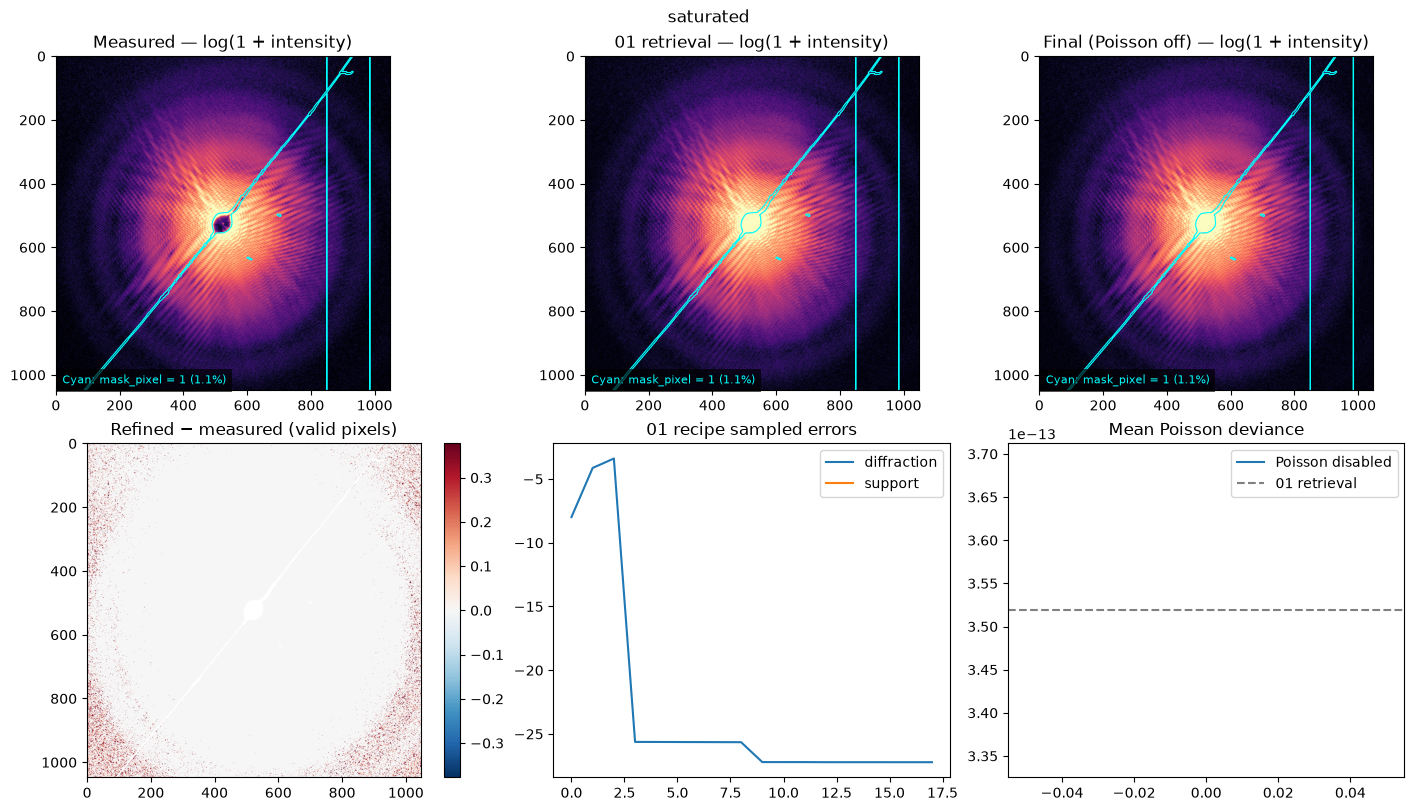

[1/96] saturated: 0.0204985 → 0.0204985; disabled_matching_01
[2/96] loop_0000: 0.0212415 → 0.0212415; disabled_matching_01
Point 1: full saturated + loop recipe; intensity factor=0.991877, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[3/96] loop_0001: 0.0207901 → 0.0207901; disabled_matching_01
Point 2: full saturated + loop recipe; intensity factor=0.98903, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[4/96] loop_0002: 0.0211245 → 0.0211245; disabled_matching_01
Point 3: full saturated + loop recipe; intensity factor=0.995402, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[8/96] loop_0006: 0.0210291 → 0.0210291; disabled_matching_01
Point 7: full saturated + loop recipe; intensity factor=0.993292, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[9/96] loop_0007: 0.0212697 → 0.0212697; disabled_matching_01
Point 8: full saturated + loop recipe; intensity factor=0.994236, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

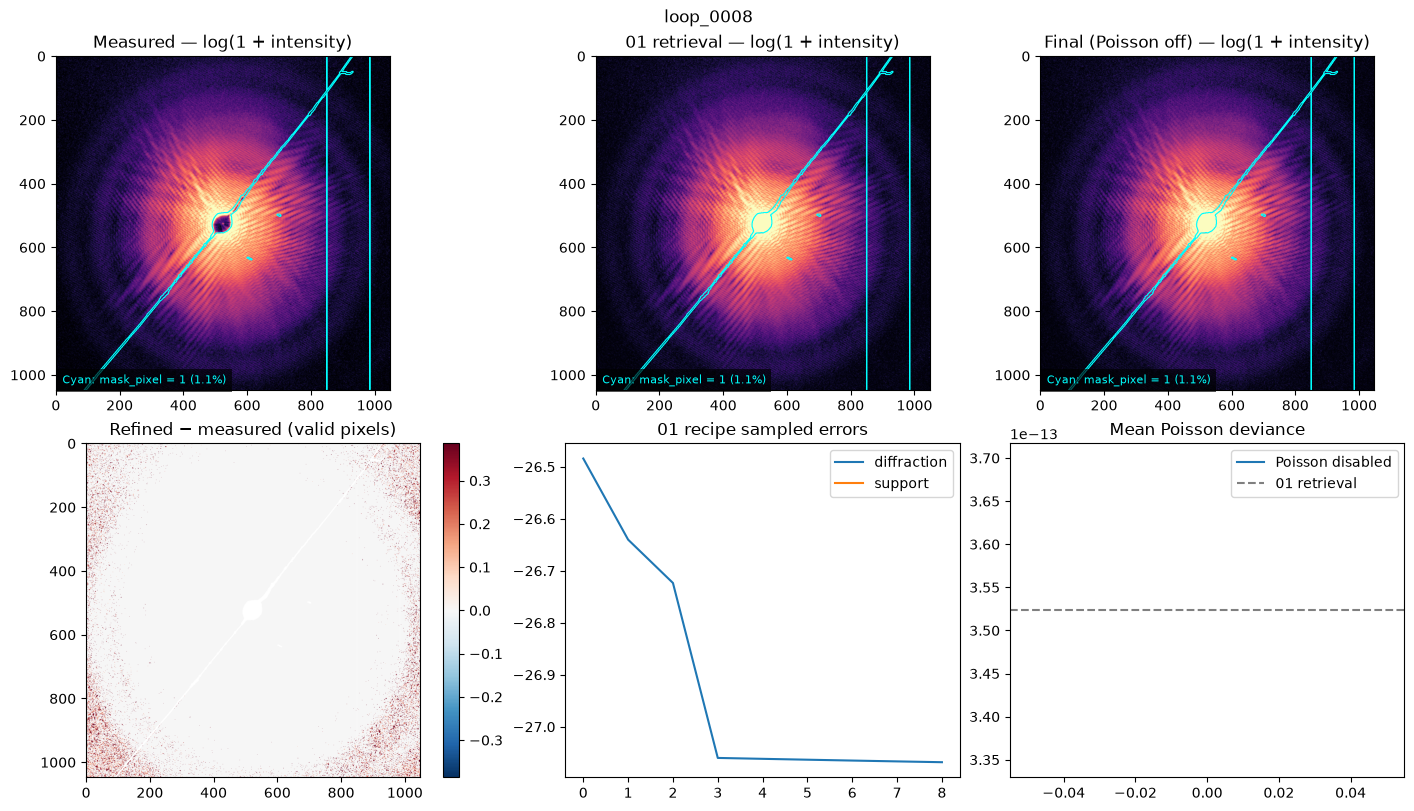

[10/96] loop_0008: 0.0208922 → 0.0208922; disabled_matching_01
Point 9: full saturated + loop recipe; intensity factor=0.989261, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[11/96] loop_0009: 0.021224 → 0.021224; disabled_matching_01
Point 10: full saturated + loop recipe; intensity factor=0.990292, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[12/96] loop_0010: 0.0206662 → 0.0206662; disabled_matching_01
Point 11: full saturated + loop recipe; intensity factor=0.987435, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[18/96] loop_0016: 0.0204409 → 0.0204409; disabled_matching_01
Point 17: full saturated + loop recipe; intensity factor=0.980055, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[19/96] loop_0017: 0.0208758 → 0.0208758; disabled_matching_01
Point 18: full saturated + loop recipe; intensity factor=0.975495, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

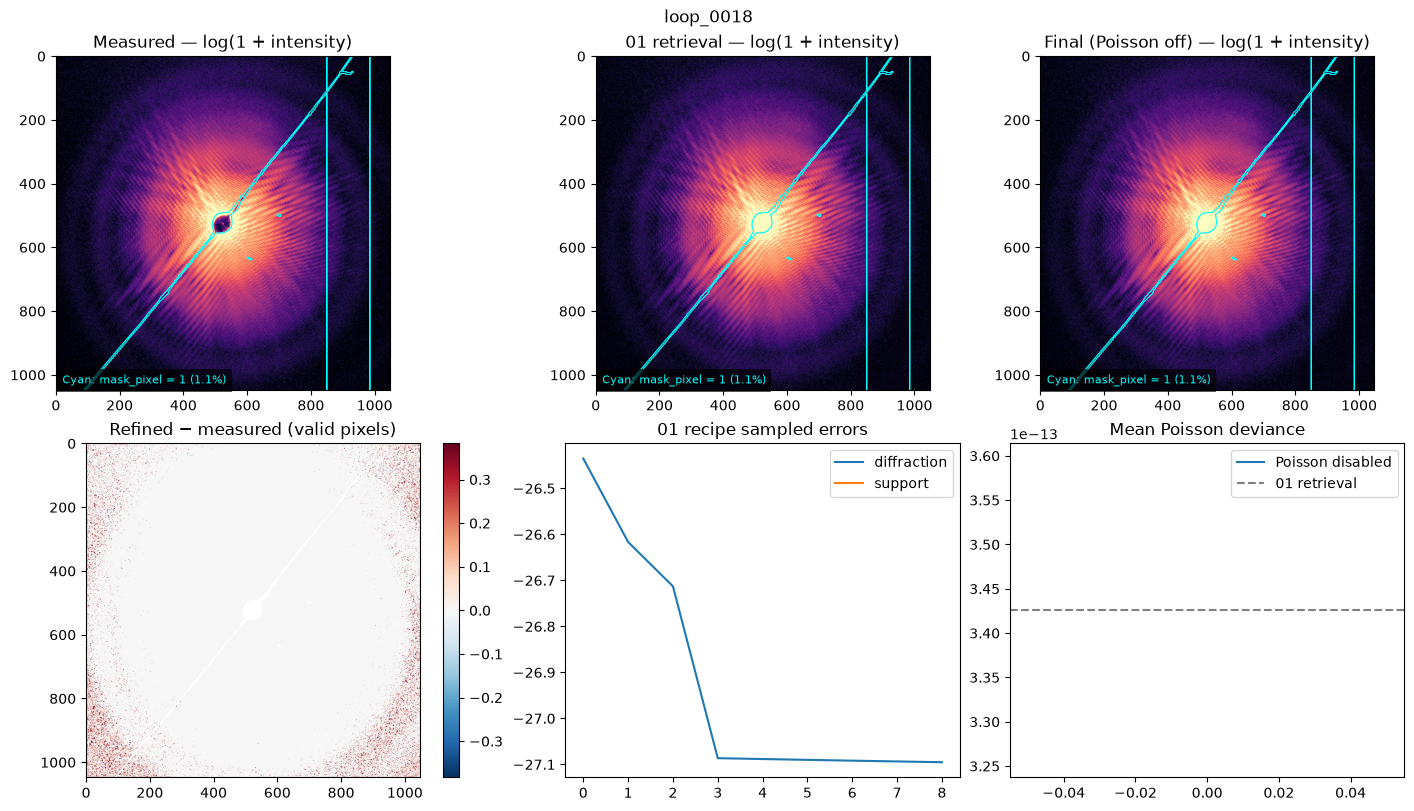

[20/96] loop_0018: 0.0207236 → 0.0207236; disabled_matching_01
Point 19: full saturated + loop recipe; intensity factor=0.971457, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[21/96] loop_0019: 0.0201194 → 0.0201194; disabled_matching_01
Point 20: full saturated + loop recipe; intensity factor=0.972428, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[22/96] loop_0020: 0.0205413 → 0.0205413; disabled_matching_01
Point 21: full saturated + loop recipe; intensity factor=0.971291, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[28/96] loop_0028: 0.0196038 → 0.0196038; disabled_matching_01
Point 29: full saturated + loop recipe; intensity factor=0.941045, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[29/96] loop_0029: 0.0204964 → 0.0204964; disabled_matching_01
Point 30: full saturated + loop recipe; intensity factor=0.937804, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

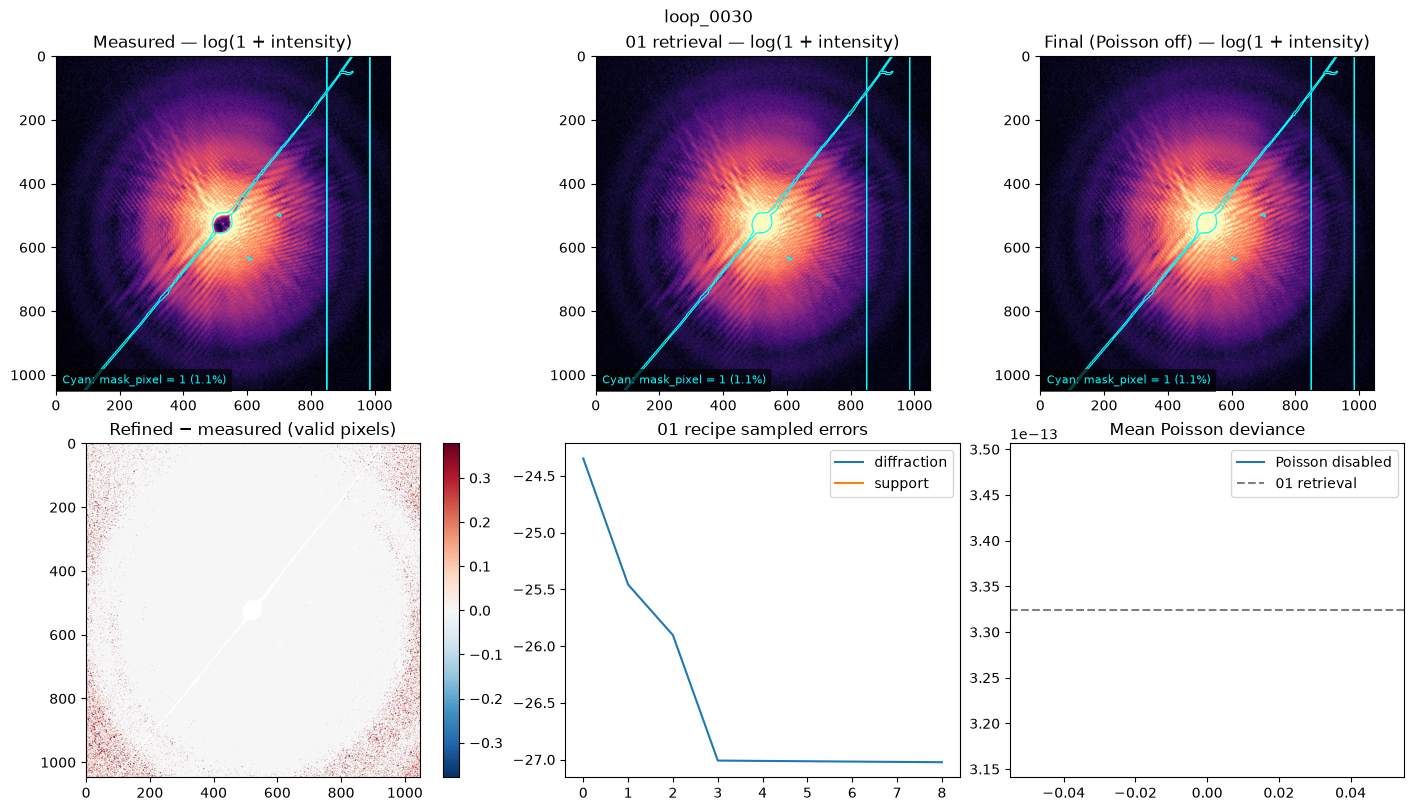

[30/96] loop_0030: 0.0199718 → 0.0199718; disabled_matching_01
Point 31: full saturated + loop recipe; intensity factor=0.921846, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[31/96] loop_0031: 0.0205096 → 0.0205096; disabled_matching_01
Point 33: full saturated + loop recipe; intensity factor=0.917633, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[32/96] loop_0033: 0.020212 → 0.020212; disabled_matching_01
Point 34: full saturated + loop recipe; intensity factor=0.913815, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[38/96] loop_0040: 0.0197707 → 0.0197707; disabled_matching_01
Point 41: full saturated + loop recipe; intensity factor=0.888567, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[39/96] loop_0041: 0.0199483 → 0.0199483; disabled_matching_01
Point 42: full saturated + loop recipe; intensity factor=0.884027, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

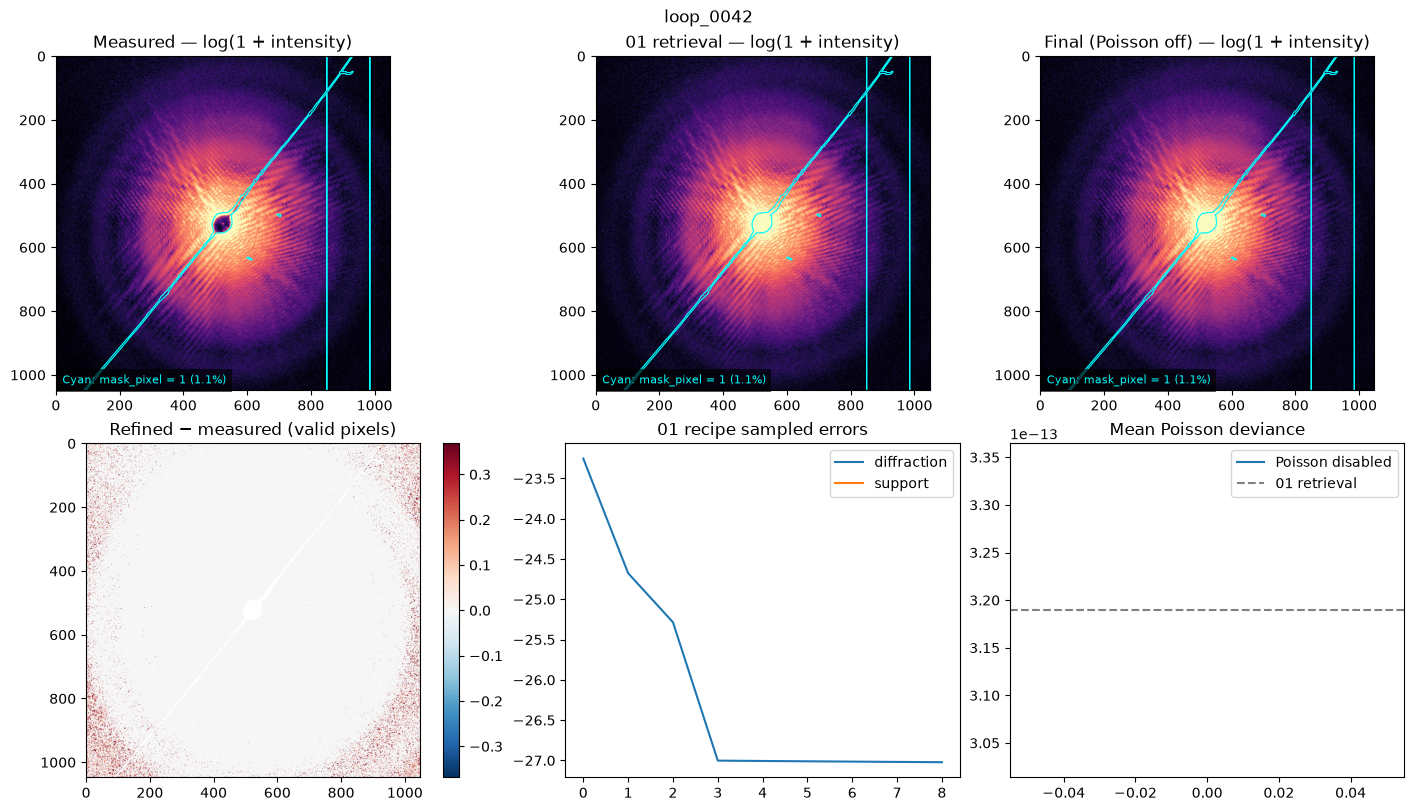

[40/96] loop_0042: 0.0200864 → 0.0200864; disabled_matching_01
Point 43: full saturated + loop recipe; intensity factor=0.882057, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[41/96] loop_0043: 0.020585 → 0.020585; disabled_matching_01
Point 44: full saturated + loop recipe; intensity factor=0.878365, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[42/96] loop_0044: 0.0207783 → 0.0207783; disabled_matching_01
Point 45: full saturated + loop recipe; intensity factor=0.874439, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[48/96] loop_0051: 0.0205367 → 0.0205367; disabled_matching_01
Point 52: full saturated + loop recipe; intensity factor=0.855522, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[49/96] loop_0052: 0.0204761 → 0.0204761; disabled_matching_01
Point 53: full saturated + loop recipe; intensity factor=0.8464, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

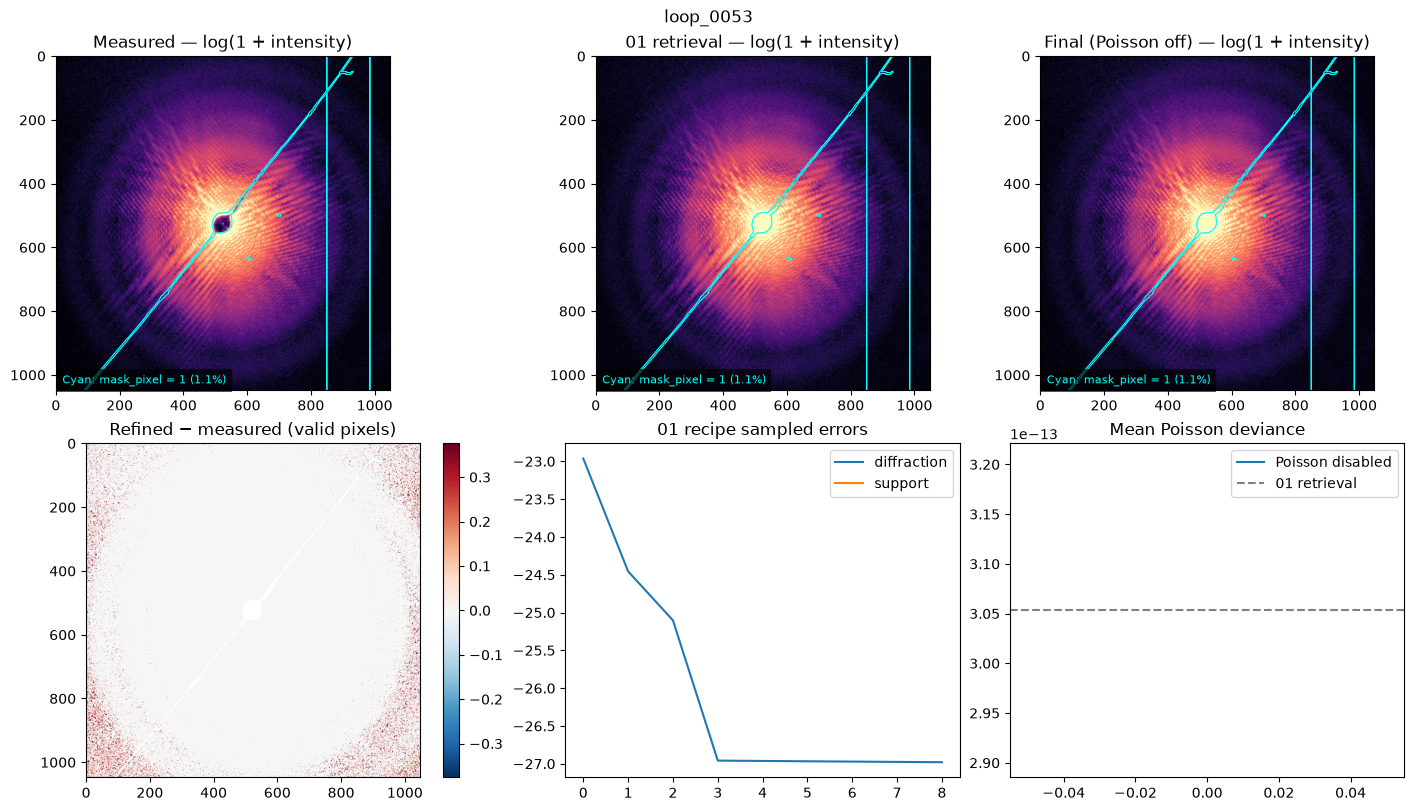

[50/96] loop_0053: 0.0210312 → 0.0210312; disabled_matching_01
Point 54: full saturated + loop recipe; intensity factor=0.83765, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[51/96] loop_0054: 0.0214769 → 0.0214769; disabled_matching_01
Point 55: full saturated + loop recipe; intensity factor=0.840713, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[52/96] loop_0055: 0.0211728 → 0.0211728; disabled_matching_01
Point 56: full saturated + loop recipe; intensity factor=0.84305, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[58/96] loop_0061: 0.0203272 → 0.0203272; disabled_matching_01
Point 62: full saturated + loop recipe; intensity factor=0.821803, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[59/96] loop_0062: 0.0207709 → 0.0207709; disabled_matching_01
Point 63: full saturated + loop recipe; intensity factor=0.820878, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

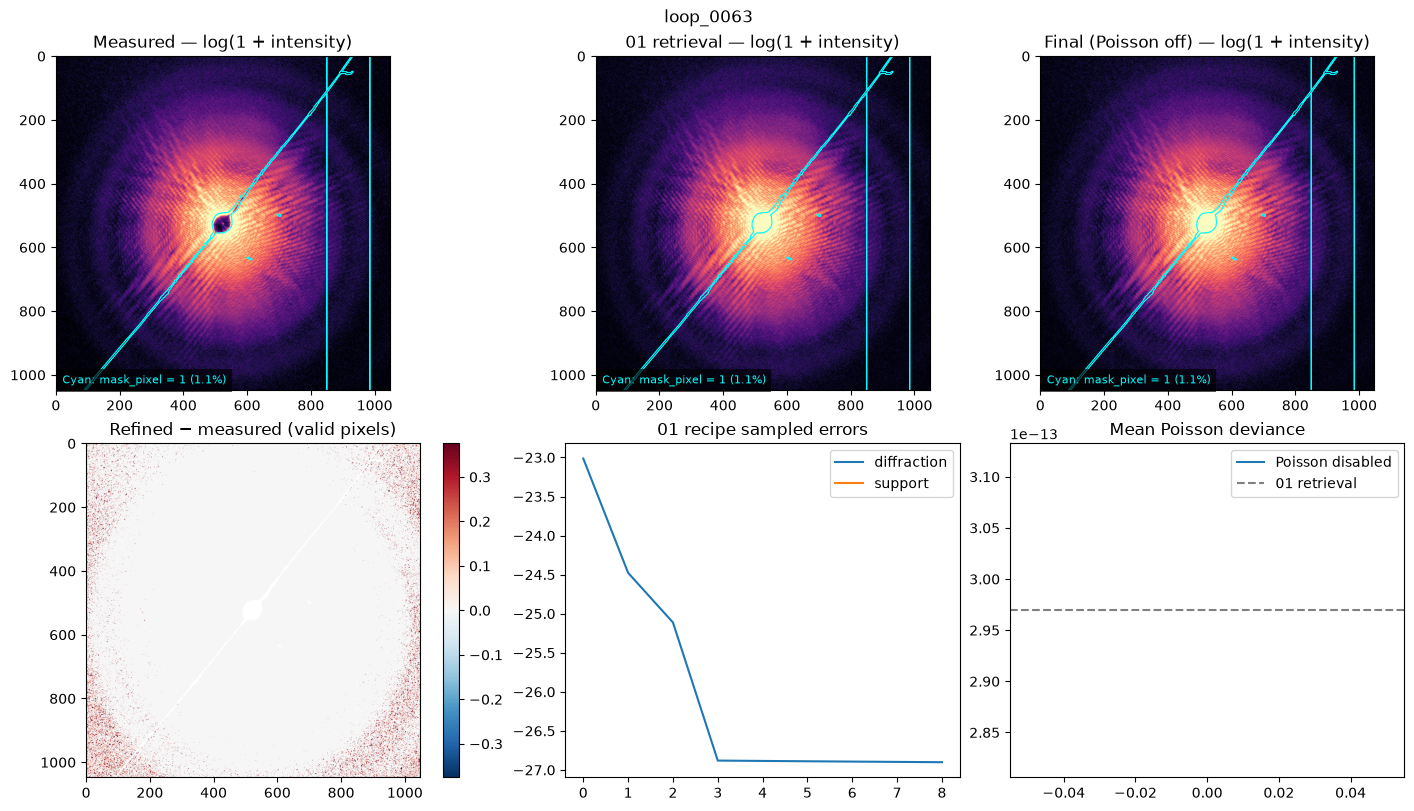

[60/96] loop_0063: 0.0208509 → 0.0208509; disabled_matching_01
Point 64: full saturated + loop recipe; intensity factor=0.818585, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[61/96] loop_0064: 0.0207978 → 0.0207978; disabled_matching_01
Point 65: full saturated + loop recipe; intensity factor=0.816982, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[62/96] loop_0065: 0.0208022 → 0.0208022; disabled_matching_01
Point 66: full saturated + loop recipe; intensity factor=0.812928, normalization applied=False


...

Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[65/96] loop_0068: 0.0210061 → 0.0210061; disabled_matching_01
Point 69: full saturated + loop recipe; intensity factor=0.808801, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

[66/96] loop_0069: 0.0215235 → 0.0215235; disabled_matching_01
Point 70: full saturated + loop recipe; intensity factor=0.805215, normalization applied=False


Phase retrieval:   0%|          | 0/3 [00:00<?, ?stage/s]

In [ ]:
OUTPUT = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT.mkdir(parents=True, exist_ok=False)
settings = {key: value for key, value in globals().copy().items() if key.isupper()
            and isinstance(value, (str, int, float, bool, list, tuple, dict, Path, type(None)))}
(OUTPUT / "source_03.ipynb").write_bytes(
    (HERE / "03_sequential_hysteresis_warmup_poisson.ipynb").read_bytes())
(OUTPUT / "recipe.json").write_text(json.dumps(recipe, default=str, indent=2))
# Snapshot the source masks/support for a reproducible comparison with 01.
with h5py.File(OUTPUT / "retrieval_inputs.h5", "w") as inputs_snapshot:
    inputs_snapshot.create_dataset("mask_pixel", data=mask_pixel, compression="gzip")
    inputs_snapshot.create_dataset("support_after_adjustment", data=support_after_adjustment, compression="gzip")
    inputs_snapshot.create_dataset("support_recentered", data=source_support, compression="gzip")
    inputs_snapshot.attrs["support_source_shift"] = support_source_shift
    inputs_snapshot.attrs["support_adjustment_json"] = json.dumps(support_adjustment)

(OUTPUT / "settings.json").write_text(json.dumps(settings, default=str, indent=2))
summary = []
with h5py.File(CACHE, "r") as cache:
    reference_state = None
    saturated_poisson_primary = None
    for position, index in enumerate(observation_indices):
        label = "saturated" if index is None else f"loop_{point_numbers[index]:04d}"
        point_number = -1 if index is None else int(point_numbers[index])
        current = saturated_current if index is None else float(currents[index])
        source_file = "saturated_hologram" if index is None else file_names[index]
        folder = OUTPUT / label
        folder.mkdir()
        # Run the actual 01 driver, keeping only this pair in memory.
        # Reuse the first computed pair for the first loop point after saving saturation.
        if index is None or position > 1:
            pair_index = indices[0] if index is None else index
            reference = cache["saturated_hologram"][()]
            loop_image = cache["loop_holograms"][pair_index]
            intensity_factor, fitted_offset = fit_reference_intensity(
                loop_image, reference, mask_pixel,
            )
            loop_for_retrieval = (loop_image / intensity_factor
                                  if NORMALIZE_LOOP_INTENSITY else loop_image)
            holograms = {
                "saturated": reference + HOLOGRAM_OFFSET,
                "loop": loop_for_retrieval + HOLOGRAM_OFFSET,
            }
            print(f"Point {point_numbers[pair_index]}: full saturated + loop recipe; "
                  f"intensity factor={intensity_factor:.6g}, "
                  f"normalization applied={NORMALIZE_LOOP_INTENSITY}", flush=True)
            # Same public driver and inputs as 01; no separate warmup implementation.
            with retrieval_progress(recipe, kind="unified"):
                pair_result = pr.phase_retrieval_algorithm(
                    holograms, mask_pixel, source_support, recipe,
                )
            # Crop/bin a diagnostic copy of the measured data on the same grid.
            prepared, _, _, _, _ = geometry.prepare(
                np.stack(list(holograms.values())), mask_pixel, source_support,
                dict(crop=recipe["crop"], binning=recipe["binning"], roi=None),
            )
            pair_measured = dict(zip(holograms, prepared))
            del reference, loop_image, loop_for_retrieval, holograms, prepared
        state_key = "saturated" if index is None else "loop"
        fields_key = "partial_coherence" if USE_PARTIAL_COHERENCE else "full_coherence"
        warmup = np.asarray(pair_result[fields_key][state_key])
        if warmup.ndim == 2:
            warmup = warmup[None]
        measured = pair_measured[state_key]
        mask = pair_result["mask_pixel"]
        effective_mask = pair_result["bsmasks"][state_key]
        supports = pair_result["supportmask"]
        if supports.ndim == 2:
            supports = supports[None]
        source_shift = support_source_shift
        modal_shifts = pair_result["mode_support_shifts"]
        histories = [dict(mode=step["mode"], iterations=step["Nit"],
                          diffraction=step["error"], support=step["support_error"])
                     for step in pair_result["error"]["steps"] if step["helicity"] == state_key]
        if index is None:
            reference_state = (warmup.copy(), measured.copy(), effective_mask.copy())
        if RUN_POISSON_REFINEMENT:
            result = poisson.refine_poisson(
                warmup, measured, supports, effective_mask, steps=POISSON_STEPS,
                learning_rate=POISSON_LEARNING_RATE, refine_modes=POISSON_REFINE_MODES,
            )
        else:
            score = poisson.poisson_deviance(poisson.predicted_intensity(warmup), measured, effective_mask)
            result = poisson.PoissonRefinementResult(
                fields=warmup.copy(), loss=np.array([score]), step_sizes=np.array([]),
                baseline_loss=score, valid_pixels=int(poisson.valid_pixels(measured, effective_mask).sum()),
                zero_pixels=0, status="disabled_matching_01",
            )
        if index is None:
            saturated_poisson_primary = result.fields[0].copy()
            DIAGNOSTIC_ROI = (geometry.support_bounding_roi(supports[0], DIAGNOSTIC_ROI_PADDING)
                              if focus_roi is None else focus_roi)
            focus_metadata = dict(
                operation="focused state minus focused saturation; shift then ROI",
                primary_mode=0, focus=focus_settings, settings_source=focus_settings_source,
                experimental_setup=DISPLAY_SETUP, scale_percentiles=[1, 99],
                roi=[[part.start, part.stop, part.step] for part in DIAGNOSTIC_ROI],
                references={"warmup": "saturated/warmup_fields[0]",
                            "poisson": "saturated/poisson_fields[0]"})
            (OUTPUT / "focus_settings.json").write_text(json.dumps(focus_metadata, indent=2))
            differences = {}
        else:
            differences = {
                "warmup": focused_difference(warmup[0], reference_state[0][0],
                                             DIAGNOSTIC_ROI, focus_settings, DISPLAY_SETUP),
                "poisson": focused_difference(result.fields[0], saturated_poisson_primary,
                                              DIAGNOSTIC_ROI, focus_settings, DISPLAY_SETUP),
            }
        scores = [poisson.poisson_deviance(poisson.predicted_intensity(fields), measured, mask)
                  for fields in (warmup, result.fields)]
        temporary = folder / "result.partial.h5"
        with h5py.File(temporary, "w") as h:
            h.attrs["preprocess_config_json"] = json.dumps(cache_config)
            h.attrs["source_cache"] = str(CACHE)
            h.attrs.update(schema_version=2, saturated_scan=SATURATED_SCAN, loop_scan=LOOP_SCAN,
                           source_scan=SATURATED_SCAN if index is None else LOOP_SCAN,
                           observation_order=position, current_units="A",
                           current_source=saturated_current_source if index is None else "cache loop_current_A[cache_index]",
                           current_available=bool(np.isfinite(current)),
                           source_support_file=str(SUPPORT_PNG),
                           recipe_json=json.dumps(recipe, default=str),
                           recipe_source="03 editable recipe initialized from 01",
                           poisson_refinement_enabled=RUN_POISSON_REFINEMENT,
                           mask_policy="fixed notebook 01 source mask for every state",
                           support_adjustment_json=json.dumps(support_adjustment),
                           mask_reference_point_number=RESOLVED_MASK_REFERENCE_POINT_NUMBER,
                           mask_pixel_png=str(MASK_PIXEL_PNG) if USE_PAINTED_MASK_PIXEL else "",
                           mask_pixel_rule="pure red RGB(255,0,0), centered cache detector grid; union with separately stored automatic masks; legacy combined masks ignored",
                           retrieval_crop=RETRIEVAL_CROP, retrieval_binning=RETRIEVAL_BINNING,
                           created_utc=datetime.now(timezone.utc).isoformat())
            if index is None:
                h.create_dataset("source_current_A", data=np.atleast_1d(saturated_currents))
                h.attrs["source_files_json"] = json.dumps(saturated_source_files)
            else:
                h.attrs["source_files_json"] = json.dumps([source_file])
            h.create_dataset("painted_mask_pixel_source", data=painted_detector_mask, compression="gzip")
            h.attrs["source_detector_shape"] = source_shape
            h.attrs["reconstruction_shape"] = warmup.shape[-2:]
            h.attrs.update(cache_index=-1 if index is None else index, point_number=point_number,
                           current_A=current, source_file=source_file,
                           energy_eV=energy_ev, status=result.status,
                           baseline_loss=result.baseline_loss, valid_pixels=result.valid_pixels,
                           zero_pixels=result.zero_pixels, settings_json=json.dumps(settings, default=str),
                           source_support_shift=source_shift, field_domain="centered Fourier")
            for key, value in dict(measured=measured, mask=mask, effective_mask=effective_mask, modal_supports=supports,
                                   warmup_fields=warmup, poisson_fields=result.fields,
                                   poisson_loss=result.loss, poisson_step_sizes=result.step_sizes,
                                   stage_deviance=scores, modal_support_shifts=modal_shifts).items():
                h.create_dataset(key, data=value, compression="gzip")
            save_complex_reconstructions(
                h, {"warmup": warmup, "poisson": result.fields}, display_object,
                dict(focus_um=DISPLAY_PROP_UM, phase_rad=DISPLAY_PHASE_RAD,
                     experimental_setup=DISPLAY_SETUP))
            if differences:
                group = h.create_group("focused_differences")
                group.attrs["display_settings_json"] = json.dumps(focus_metadata)
                group.attrs["field_domain"] = "focused, shifted object-space ROI"
                for stage, difference in differences.items():
                    group.create_dataset(stage, data=np.asarray(difference, dtype=np.complex128), compression="gzip")
            for stage, record in enumerate(histories):
                group = h.create_group(f"warmup_history/{stage}")
                group.attrs.update(mode=record["mode"], iterations=record["iterations"])
                for key in ("diffraction", "support"):
                    group.create_dataset(key, data=record[key])
        temporary.replace(folder / "result.h5")
        save_plots(folder, label, measured, mask, warmup, result, histories,
                   show=(position == 0 or position == len(observation_indices) - 1 or (position + 1) % SHOW_EVERY == 0))
        summary.append(dict(cache_index=-1 if index is None else index, point_number=point_number,
                            current_A=current, warmup_deviance=scores[0],
                            poisson_deviance=scores[1], status=result.status))
        with (OUTPUT / "summary.csv").open("w", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
            writer.writeheader(); writer.writerows(summary)
        print(f"[{position + 1}/{len(observation_indices)}] {label}: {scores[0]:.6g} → {scores[1]:.6g}; {result.status}", flush=True)
        del measured, mask, supports, warmup, result, histories, differences
        if index is not None:
            del pair_result, pair_measured
print("Saved all results to", OUTPUT)
# All complex ROIs are already saved; reread one state at a time for shared scaling.
focus_metadata = export_difference_sequence(OUTPUT, summary, focus_metadata)

if SAVE_INDIVIDUAL_MODE_PNGS:
    reconstruction_png_metadata = export_reconstruction_pngs(OUTPUT, summary)


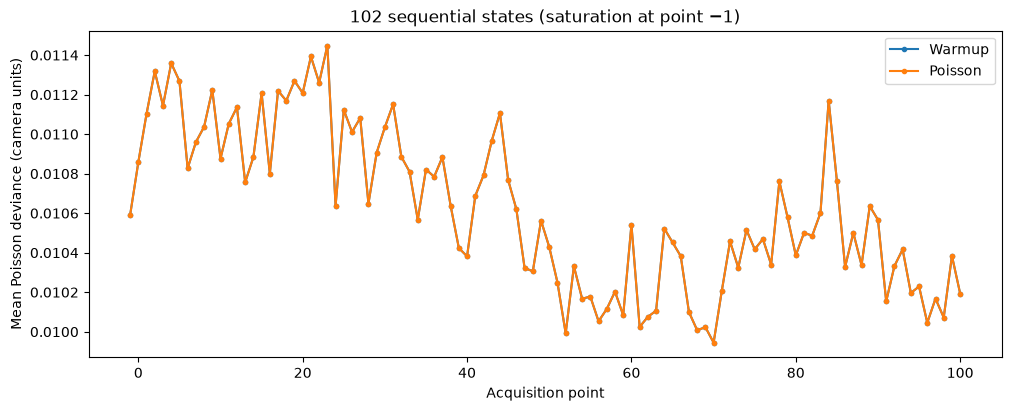

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for key, label in [("warmup_deviance", "Warmup"), ("poisson_deviance", "Poisson")]:
    ax.plot([row["point_number"] for row in summary], [row[key] for row in summary], ".-", label=label)
ax.set(xlabel="Acquisition point", ylabel="Mean Poisson deviance (camera units)",
       title=f"{len(summary)} sequential states (saturation at point −1)")
ax.legend()
fig.savefig(OUTPUT / "loop_diagnostics.png", dpi=160)
plt.show()